# Replicate overlap - May 12, 2015
Count how many peptides (aka phoshorylation sites) appear in the three mass spec replicates and their overlaps

## Initializations

In [2]:
import os, csv
from matplotlib_venn import venn3, venn3_unweighted

dataDir = os.path.join('..','..','phosphorylation-data-sets','McKenna2014')
repAFile = os.path.join(dataDir, 'simplified_biological_replicate_A_orig.txt')
repBFile = os.path.join(dataDir, 'simplified_biological_replicate_B_orig.txt')
repCFile = os.path.join(dataDir, 'simplified_biological_replicate_C_orig.txt')

## Load the peptide lists
Print the number of peptides in each replicate and the size of the union of all replicates

In [15]:
fileList = [repAFile, repBFile, repCFile]
labels = ["Replicate A", "Replicate B", "Replicate C"]
peptideLists = []
for curFile in fileList:
    with open(curFile) as f:
        reader = csv.DictReader(f, delimiter = '\t')
        peptideLists.append({row['peptide'].upper() for row in reader})

peptideUnion = set()
for rep in range(len(fileList)):
    print "%s peptides: %d" % (labels[rep], len(peptideLists[rep]))
    peptideUnion.update(peptideLists[rep])
    
print "All unique peptides (replicate union): %d" % len(peptideUnion)

Replicate A peptides: 2877
Replicate B peptides: 3082
Replicate C peptides: 2917
All unique peptides (replicate union): 5442


## Plot the overlaps

Populating the interactive namespace from numpy and matplotlib


`%matplotlib` prevents importing * from pylab and numpy


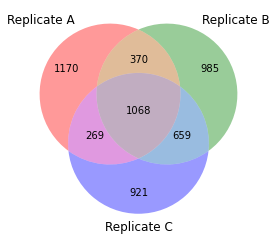

In [16]:
%pylab inline

venn3_unweighted(peptideLists, labels)
show()